<a href="https://colab.research.google.com/github/GabrielBorre/TP_IA_Algoritmp_Genetico_Canciones/blob/main/Algoritmo_Gen%C3%A9tico_Canciones.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#@title
!pip install deap

# instala paquetes gráficos
!apt-get install -y graphviz-dev
!pip install pygraphviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 14.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [deap]
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Note, selecting 'libgraphviz-dev' instead of 'graphviz-dev'
The following additional packages will be installed:
  at-spi2-common libatk1.0-0t64 libgail-common libgail18t64 libgtk2.0-0t64
  libgtk2.0-bin libgtk2.0-common libgvc6-plugins-gtk librsvg2-common
  libxcomposite1 libxdot4
Suggested packages:
  gvfs
The following NEW packages will be installed:
  at-spi2-common libatk1.0-0t64 libgail-common libgail18t64 libgraphviz-dev
  libgtk2.0-0t64 libgtk2.0-bin libgtk2.0-common libgvc6-plugins-gtk
  librsvg2-common libxcomposite1 libxdot4
0 upgraded, 12 newly installed, 0 to remove and 0 not upgraded.
Need to get 2,460 kB of archives.
After this operation, 7,657 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/main amd64 at-s

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#@title
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from __future__ import division
import numpy as np
from scipy import spatial
import matplotlib as mpl
from matplotlib import cm
import copy

import math
from deap import base
from deap import creator
from deap import tools

import matplotlib
import matplotlib.pyplot as plt
import networkx
from IPython.display import display
from PIL import Image

print("\nLibrerías importadas")


Librerías importadas


In [ ]:
#@title PARÁMETROS

#@markdown Parámetros del AG:

# Cantidad de Ciclos de la Corrida
CANT_CICLOS =   100#@param {type:"integer"}


# Cantidad de Individuos en la Población
CANT_INDIVIDUOS_POBLACION = 15 #@param {type:"integer"}
if CANT_INDIVIDUOS_POBLACION < 5:
  CANT_INDIVIDUOS_POBLACION = 5

In [ ]:
import os


# Reemplaza 'NombreDeTuCarpeta' y 'datos.csv' por los nombres reales de tu carpeta y archivo
ruta = '/content/drive/MyDrive/TP AG/catalogo_100_canciones.csv'
df = pd.read_csv(ruta)

# 3. Mostrar todo el DataFrame
df.head()



,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,53203,2prnn41CblB8B4yWACDljP,Shouse;David Guetta,Love Tonight (David Guetta Remix),Love Tonight - David Guetta Remix Edit,81,158095,False,0.621,0.989,...,-4.225,0,0.0434,0.0150,0.3570,0.1840,0.0348,126.002,4,house
1,53064,24Yi9hE78yPEbZ4kxyoXAI,SAINt JHN;Imanbek,Roses (Imanbek Remix),Roses - Imanbek Remix,81,176840,True,0.770,0.724,...,-5.484,1,0.0495,0.0167,0.0107,0.3530,0.8980,121.975,4,house
2,23100,3XucsgiwXb8KPn9Csf9Zmu,James Hype;Miggy Dela Rosa;Lazza,Ferrari (Remix),Ferrari - Remix,80,172000,False,0.818,0.728,...,-5.705,0,0.0724,0.0985,0.0000,0.0917,0.5970,124.974,4,deep-house
3,53301,11kDth1aKUEUMq9r1pqyds,Travis Scott,ASTROWORLD,5% TINT,79,196138,True,0.712,0.481,...,-5.415,0,0.0487,0.1730,0.0000,0.2410,0.0620,140.000,4,house
4,53351,2cYqizR4lgvp4Qu6IQ3qGN,Travis Scott,ASTROWORLD,BUTTERFLY EFFECT,79,190557,False,0.763,0.628,...,-5.850,1,0.0500,0.0531,0.0000,0.1140,0.1930,140.958,4,house


In [ ]:
total = df['duration_ms'].sum()
promedio_en_minutos=total/(1000*60)/100

print("Promedio de duracion de las canciones en minutos :" ,promedio_en_minutos)

Promedio de duracion de las canciones en minutos : 3.7889364999999997


In [ ]:
#@markdown > **Descripción del Modelo de Aptitud:**
#@markdown
#@markdown La función de aptitud evalúa la calidad de una lista de reproducción (setlist) combinando el cumplimiento de objetivos musicales clave con una penalización proporcional por transiciones abruptas.
#@markdown
#@markdown **1. Fórmula de Aptitud Base (F):**
#@markdown Busca maximizar una puntuación ponderada de siete características fundamentales:
#@markdown - **Continuidad del Tempo (T, 25%)**: Premia las transiciones con una diferencia menor o igual a 20 BPM para mantener una velocidad constante y fluida.
#@markdown - **Progresión de Energía (E, 20%)**: Favorece el desarrollo ascendente de la intensidad energética entre canciones consecutivas.
#@markdown - **Instrumentalidad (I, 20%)**: Premia la presencia promedio de pistas con mayor carácter instrumental según la orientación de la sesión.
#@markdown - **Compatibilidad Armónica (H, 10%)**: Beneficia transiciones que comparten la misma tonalidad (combinación exacta de modo y clave).
#@markdown - **Compatibilidad de Género (G, 10%)**: Premia la continuidad directa del mismo género musical en transiciones sucesivas.
#@markdown - **Bailabilidad (D, 10%)**: Promueve que la capacidad de baile se mantenga o incremente de un tema al siguiente.
#@markdown - **Variedad de Artistas (V, 5%)**: Valora positivamente que la lista cuente con una distribución diversa de artistas distintos.
#@markdown
#@markdown **2. Penalización Gradual (P):**
#@markdown Reduce la aptitud final de forma proporcional a los errores cometidos en las transiciones consecutivas:
#@markdown - **NT (2,5%)**: Cantidad de saltos de tempo mayores a 20 BPM.
#@markdown - **NE (2,5%)**: Caídas repentinas de energía (mayores a 0.3).
#@markdown - **NL (5%)**: Diferencias bruscas en la sonoridad o volumen (mayores a 5 dB).
#@markdown
#@markdown **3. Penalizaciones Excluyentes (Filtros duros):**
#@markdown Establece una aptitud mínima por defecto de 0.001 si el setlist no cumple con los límites estrictos de duración (57-63 minutos), repite alguna canción o incluye más de 2 canciones del mismo artista.

## Inicializa objeto Toolbox auxiliar
toolbox = base.Toolbox()

# Indica que la función de aptitud es para maximizar
creator.create("Fitness", base.Fitness, weights=(1.0,))

# Genero Familia de pares
FAMILIA = {
    'house': 'house', 'progressive-house': 'house',
    'chicago-house': 'house', 'deep-house': 'house',
    'techno': 'techno', 'minimal-techno': 'techno',
    'detroit-techno': 'techno',
    'groove': 'puente',
}
# Compara los generos si pertenece a una familia
def compat_genero(g1, g2):
    if g1 == g2:
        return 1.0
    f1, f2 = FAMILIA.get(g1), FAMILIA.get(g2)
    if f1 == f2:
        return 0.7
    if f1 == 'puente' or f2 == 'puente':
        return 0.4
    return 0.1

def funcAptitud(individual):
    # Si el setlist es demasiado corto para evaluar transiciones, su aptitud es mínima
    if len(individual) < 2:
        return 0.001,

    # ==========================================
    # 1. PENALIZACIONES EXCLUYENTES (Filtros duros)
    # ==========================================

    # A. Repeticiones: Ninguna canción duplicada permitida
    if len(individual) != len(set(individual)):
        return 0.001,

    # B. Duración: Debe estar estrictamente entre 57 y 63 minutos (en milisegundos)
    # 57 minutos = 3,420,000 ms | 63 minutos = 3,780,000 ms
    duracion_total_ms = df.iloc[individual]['duration_ms'].sum()
    if not (3420000 <= duracion_total_ms <= 3780000):
        return 0.001,

    # C. Artistas: Máximo 2 temas por artista
    artistas_setlist = list(df.iloc[individual]['artists'])
    for artista in set(artistas_setlist):
        if artistas_setlist.count(artista) > 2:
            return 0.001,


    # Obtener las canciones del cromosoma
    canciones = df.iloc[individual]

    # Restricción: mínimo 3 géneros distintos
    generos_distintos = canciones["track_genre"].nunique()

    if generos_distintos < 3:
        return 0.001,

    # Identificar las 50 canciones más populares del catálogo
    top_50_indices = set(
        df["popularity"]
        .reset_index(drop=True)
        .nlargest(50)
        .index
    )

    # Contar cuántas canciones del cromosoma están en el Top 50
    cantidad_populares = sum(
        indice in top_50_indices
        for indice in individual
    )

    if cantidad_populares < 5:
        return 0.001,

    # ==========================================
    # 2. EVALUACIÓN DE COMPONENTES BASE (F)
    # ==========================================

    # Inicialización de componentes individuales y de transiciones
    continuidad_tempo = 0.0      # T (Peso 0.25)
    progresion_energia = 0.0     # E (Peso 0.20)
    instrumentalidad = 0.0       # I (Peso 0.20)
    compatibilidad_armonica = 0.0# H (Peso 0.10)
    compatibilidad_genero = 0.0  # G (Peso 0.10)
    bailabilidad = 0.0           # D (Peso 0.10)
    variedad_artistas = 0.0      # V (Peso 0.05)

    # Variables contadoras para la penalización gradual (P)
    cantidad_transiciones_exceso_tempo = 0     # NT (Salto tempo > 20 BPM)
    cantidad_transiciones_bruscas_energia = 0  # NE (Bajada de energía > 0.3)
    cantidad_transiciones_exceso_volumen = 0   # NL (Salto volumen > 5 dB)

    # V - Variedad de artistas: proporción de artistas únicos
    artistas_unicos = set(artistas_setlist)
    variedad_artistas = len(artistas_unicos) / len(individual)

    # Evaluación iterativa a lo largo del setlist
    for i in range(len(individual)):
        cancion_actual = df.iloc[individual[i]]

        # I - Sumamos instrumentalidad de cada pista individual
        instrumentalidad += cancion_actual['instrumentalness']

        if i < len(individual) - 1:
            cancion_siguiente = df.iloc[individual[i+1]]

            # --- T: Continuidad del tempo ---
            diferencia_tempo = abs(cancion_siguiente['tempo'] - cancion_actual['tempo'])
            if diferencia_tempo <= 5:
                continuidad_tempo += 1.0
            elif diferencia_tempo <= 10:
                continuidad_tempo += 0.8
            elif diferencia_tempo <= 15:
                continuidad_tempo += 0.5
            elif diferencia_tempo <= 20:
                continuidad_tempo += 0.25
            else:
                cantidad_transiciones_exceso_tempo += 1  # NT

            # --- E: Progresión de energía ---
            baja_energia = cancion_actual['energy'] - cancion_siguiente['energy']
            if baja_energia <= 0:
                progresion_energia += 1.0
            elif baja_energia <= 0.1:
                progresion_energia += 0.6
            elif baja_energia <= 0.3:
                progresion_energia += 0.3
            else:
                cantidad_transiciones_bruscas_energia += 1

            # --- H: Compatibilidad armónica ---
            if cancion_actual['key'] == cancion_siguiente['key'] and cancion_actual['mode'] == cancion_siguiente['mode']:
                compatibilidad_armonica += 1.0
            elif cancion_actual['key'] == cancion_siguiente['key']:
                compatibilidad_armonica += 0.6
            elif abs(cancion_actual['key'] - cancion_siguiente['key']) <= 1:
                compatibilidad_armonica += 0.3

            # --- G: Compatibilidad de género ---
            compatibilidad_genero += compat_genero(
            cancion_actual['track_genre'], cancion_siguiente['track_genre']
            )

            # --- D: Bailabilidad ---
            if cancion_siguiente['danceability'] >= cancion_actual['danceability']:
                bailabilidad += 1.0

            # --- NL: Saltos excesivos de volumen (Loudness) ---
            diferencia_volumen = abs(cancion_siguiente['loudness'] - cancion_actual['loudness'])
            if diferencia_volumen > 5.0:
                cantidad_transiciones_exceso_volumen += 1  # NL

    # Normalizaciones
    cantidad_transiciones = len(individual) - 1

    continuidad_tempo /= cantidad_transiciones
    progresion_energia /= cantidad_transiciones
    compatibilidad_armonica /= cantidad_transiciones
    compatibilidad_genero /= cantidad_transiciones
    bailabilidad /= cantidad_transiciones
    instrumentalidad /= len(individual)

    # ==========================================
    # 3. CÁLCULO DE LA PENALIZACIÓN GRADUAL (P)
    # ==========================================
    penalizacion_gradual = (
        (0.025 * cantidad_transiciones_exceso_tempo) +
        (0.025 * cantidad_transiciones_bruscas_energia) +
        (0.05 * cantidad_transiciones_exceso_volumen)
    ) / cantidad_transiciones

    # ==========================================
    # 4. VALOR FINAL DE APTITUD (F - P)
    # ==========================================
    aptitud_base = (
        (0.25 * continuidad_tempo) +
        (0.20 * progresion_energia) +
        (0.20 * instrumentalidad) +
        (0.10 * compatibilidad_armonica) +
        (0.10 * compatibilidad_genero) +
        (0.10 * bailabilidad) +
        (0.05 * variedad_artistas)
    )

    aptitud_final = max(0.001, aptitud_base - penalizacion_gradual)
    return aptitud_final,

# Registra la función en el toolbox de DEAP
toolbox.register("evaluate", funcAptitud)

print("\nFunción de Aptitud actualizada y registrada con las nuevas variables y penalizaciones.")

#@markdown > **Estructura del Cromosoma:**
#@markdown - El cromosoma está compuesto por una secuencia de números enteros únicos. Cada entero representa la posición física (índice de fila) de una canción dentro de nuestro DataFrame del CSV de Spotify.
creator.create("Individual", list, fitness=creator.Fitness)

#@markdown > **Configuración de Genes del Cromosoma:**
#@markdown - Registramos el creador de índices aleatorios utilizando posiciones enteras del dataset para armar la lista de reproducción.
cant_genes_cromosoma = 15 #@param {type:"integer"}
toolbox.register("indices", random.sample, range(len(df)), cant_genes_cromosoma)
toolbox.register("individual", tools.initIterate, creator.Individual, toolbox.indices)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)


Función de Aptitud actualizada y registrada con las nuevas variables y penalizaciones.


In [ ]:
#@title OPERADORES GENÉTICOS
#@markdown definidos en https://deap.readthedocs.io/en/master/api/tools.html#operators

tipo_seleccion = 'Torneo' #@param ["Azar", "Torneo", "Ranking", "Ruleta"]
tipo_cruzamiento = 'Simple-1Punto' #@param ["Simple-1Punto", "Simple-2Puntos", "Azar"]

# Probabilidad de Mutación
probab_mutacion = 0.5 #@param {type:"slider", min:0, max:1, step:0.05}

# Registrar tipo de Selección a aplicar con sus parámetros
if tipo_seleccion == 'Torneo':
  toolbox.register("select", tools.selTournament, tournsize=2)
elif tipo_seleccion == 'Ranking':
  toolbox.register("select", tools.selBest)
elif tipo_seleccion == 'Ruleta':
  toolbox.register("select", tools.selRoulette)
else:
  toolbox.register("select", tools.selRandom)

# Registrar tipo de Cruzamiento a aplicar con sus parámetros
if tipo_cruzamiento == 'Simple-1Punto':
  toolbox.register("mate", tools.cxOnePoint)
elif tipo_cruzamiento == 'Simple-2Puntos':
  toolbox.register("mate",  tools.cxTwoPoint)
else:
  toolbox.register("mate", tools.cxUniform, indpb=1/cant_genes_cromosoma)

# Registrar tipo de Mutación a aplicar con sus parámetros
# El rango de enteros va de 0 hasta len(df) - 1 (las posiciones posibles en tu CSV)
valor_max_indice_cancion = len(df) - 1
toolbox.register("mutate", tools.mutUniformInt, low=0, up=valor_max_indice_cancion, indpb=1/cant_genes_cromosoma)

print("\nOperadores Genéticos adaptados y definidos correctamente")


Operadores Genéticos adaptados y definidos correctamente


In [ ]:
# @title FUNCIONES AUXILIARES

## Define una función auxiliar para calcular estadísticas y guarda info en vectores auxiliares
def CalculoEstadisticas(ciclo, indivPobla, muestra, mejorMax = True):
    global mejorIndCorrida, mejorIndCorrida_ciclo
    global ciclosMaxAptitud
    global ciclosPromAptitud
    global ciclosMinAptitud
    if len(indivPobla) == 0:
      return None, 0, 0, 0
    auxMax = None
    auxMin = None
    auxSum = 0
    auxBestInd = None
    auxBestIndApt = None
    for ind in indivPobla:
        # Se cambia el redondeo a 10 decimales para una precisión ultra-fina de la función de aptitud
        apt = round(ind.fitness.values[0], 10)
        auxSum = auxSum + apt
        if (auxMax == None) or (apt > auxMax):
            auxMax = apt
            if mejorMax:
              auxBestInd = ind
              auxBestIndApt = apt
        if (auxMin == None) or (apt < auxMin):
            auxMin = apt
            if not mejorMax:
              auxBestInd = ind
              auxBestIndApt = apt
    auxProm = round(auxSum / len(indivPobla), 10)
    if (mejorIndCorrida == None) or (mejorIndCorrida.fitness.values < auxBestInd.fitness.values):
          mejorIndCorrida = auxBestInd
          mejorIndCorrida_ciclo = ciclo
    ciclosMaxAptitud.append( auxMax )
    ciclosPromAptitud.append( auxProm )
    ciclosMinAptitud.append( auxMin )
    if muestra:
        #print("\n-- Ciclo  %i --" % ciclo)
        print(" ++ Mejor Individuo:", auxBestInd, " {", auxBestIndApt, "}")
        print("      Max: ", auxMax, " / Promedio: ", auxProm, " / Min: ", auxMin)
    return auxBestInd, auxMax, auxProm, auxMin

def asignarAptitud(indivPobla):
  # Asigna el valor de aptitud a los individuos
  fitnesses = list(map(toolbox.evaluate, indivPobla))
  for ind, fit in zip(indivPobla, fitnesses):
      ind.fitness.values = fit


def mostrarParamsDetalle():
  print("EJECUCIÓN DE LA CORRIDA: ")
  print("	 Criterio de Paro: "+str(CANT_CICLOS)+" ciclos.")
  print("	 Tamaño de la Población: "+str(CANT_INDIVIDUOS_POBLACION)+" individuos.")
  print("	 Método de Selección: "+tipo_seleccion+".")
  print("	 Método de Cruzamiento: "+tipo_cruzamiento+".")
  print("	 Método de Mutación: Simple con "+str(probab_mutacion*100)+"% de probabilidad.")
  print("")

def mostrarPoblaDetalle(indivPobla, titulo=""):
  if titulo != "":
    print("\n" + titulo)
  for ind in indivPobla:
    print("	", ind, " { ", round(ind.fitness.values[0], 10), " } ")
  print("")

print("\nFunciones auxiliares adaptadas y definidas correctamente con 10 decimales de precisión")


Funciones auxiliares adaptadas y definidas correctamente con 10 decimales de precisión


In [ ]:
# @title EJECUCIÓN DE LA CORRIDA

# Indica si se muestra el detalle de los operadores genéticos aplicados
MOSTRAR_DETALLE = True #@param {type:"boolean"}

# Indica si se muestra el detalle de las estadísticas en cada ciclo
MUESTRA_ESTADISTICAS = True  #@param {type:"boolean"}

# Semilla del azar: misma semilla = misma corrida
SEMILLA = 42 #@param {type:"integer"}
random.seed(SEMILLA)

if MOSTRAR_DETALLE:
  mostrarParamsDetalle()

# Resetear Genelogy
history = tools.History()
# Decorate the variation operators
toolbox.decorate("mate", history.decorator)
toolbox.decorate("mutate", history.decorator)

# cálcula cantidad de individuos seleccionados como la mitad + 1
cant_ind_selecc = (CANT_INDIVIDUOS_POBLACION//2)+1

# Define la población inicial
indivPobla = toolbox.population(n=CANT_INDIVIDUOS_POBLACION)
history.update(indivPobla)

# Asigna el valor de aptitud a los individuos de la población inicial
asignarAptitud(indivPobla)

if MOSTRAR_DETALLE or MUESTRA_ESTADISTICAS:
  print("\n-- Ciclo  0 --")

if MOSTRAR_DETALLE:
  mostrarPoblaDetalle(indivPobla, "*) Población Inicial:")

# vectores auxiliares
ciclo = 1
mejorIndCorrida = None
mejorIndCorrida_ciclo = 0
ciclosIndiv = []
ciclosMaxAptitud = []
ciclosPromAptitud = []
ciclosMinAptitud = []


# Cálcula estadísticas y guarda info en vectores auxiliares
auxBestInd, auxMax, auxProm, auxMin = CalculoEstadisticas(0, indivPobla, MUESTRA_ESTADISTICAS)

# criterio de paro
while (ciclo < CANT_CICLOS):
    if MOSTRAR_DETALLE or MUESTRA_ESTADISTICAS:
      print("\n-- Ciclo  %i --" % ciclo)

    # Realiza la Selección
    indivSelecc = toolbox.select(indivPobla, cant_ind_selecc)
    if MOSTRAR_DETALLE:
      mostrarPoblaDetalle(indivSelecc, "a) Individuos Seleccionados:")

    # Realiza el Cruzamiento
    # por cada individuo seleccionado los clona (sino pueden afectarle los cambios)
    # y luego le busca una pareja al azar dentro de los seleccionados para generar 2 hijos
    if MOSTRAR_DETALLE:
      print("b) Cruzamiento: ")
    indivHijos = []
    for hijo1 in list(map(toolbox.clone, indivSelecc)):
      if len(indivHijos) < len(indivPobla):
        # todavía falta generar hijos
        hijo2 = list(map(toolbox.clone, random.sample(indivSelecc, 1)))[0]
        if MOSTRAR_DETALLE:
          print("\t", hijo1, "x", hijo2, end=" =")
        # hace el cruzamiento
        toolbox.mate(hijo1, hijo2)
        del hijo1.fitness.values
        del hijo2.fitness.values
        # agrega 1er hijo
        indivHijos.append(hijo1)
        if MOSTRAR_DETALLE:
          print("", hijo1, end="")
        if len(indivHijos) < len(indivPobla):
          # agrega 2do hijo
          indivHijos.append(hijo2)
          if MOSTRAR_DETALLE:
            print(" &", hijo2, end="")
        if MOSTRAR_DETALLE:
          print("")
      else:
        break

    # controla que mantenga que los hijos
    # tenga la misma cantidad de individuos que la población original
    if len(indivHijos) != len(indivPobla):
      print("ERROR: distinta cantidad de individuos hijos ", len(indivHijos) , " | ", len(indivPobla))

    # Realiza la Mutación
    if MOSTRAR_DETALLE:
      print("\nc) Mutación: ")
    if random.random() < probab_mutacion:
      # ejecuta mutación:
      # selecciona al azar el individuo a mutar
      # y lo muta aplicando el método
      mutant = indivHijos[random.randint(0, len(indivHijos)-1)]
      if MOSTRAR_DETALLE:
        print("\tse ejecuta: ", mutant, end=" ")
      # hace la mutación
      toolbox.mutate(mutant)
      del mutant.fitness.values
      if MOSTRAR_DETALLE:
        print("--> ", mutant, "\n")
    else:
      # no se ejecuta mutación
      print("\tNo se ejecuta\n")

    # Evalua a los individuos hijos que salen de Cruzamiento & Mutación
    #  para determinar si son válidos y su valor de aptitud
    invalid_ind = [ind for ind in indivHijos if not ind.fitness.valid]
    asignarAptitud(invalid_ind)

    # Reemplaza la población actual con los hijos
    indivPobla[:] = indivHijos
    if MOSTRAR_DETALLE:
      mostrarPoblaDetalle(indivPobla, "*) Siguiente Generación:")

    # Cálcula estadísticas y guarda info en vectores auxiliares
    auxBestInd, auxMax, auxProm, auxMin = CalculoEstadisticas(ciclo, indivPobla, MUESTRA_ESTADISTICAS)

    ciclo = ciclo + 1

print("\n-- Corrida Finalizada en %i ciclos --" % ciclo )
if mejorIndCorrida is not None:
    print("== Mejor Individuo de la Corrida aparece en ciclo ", mejorIndCorrida_ciclo, ":", mejorIndCorrida, " { ", round(mejorIndCorrida.fitness.values[0], 10), " }  ==")
else:
    print("No se pudo determinar un mejor individuo para la corrida.")

EJECUCIÓN DE LA CORRIDA: 
	 Criterio de Paro: 100 ciclos.
	 Tamaño de la Población: 15 individuos.
	 Método de Selección: Torneo.
	 Método de Cruzamiento: Simple-1Punto.
	 Método de Mutación: Simple con 50.0% de probabilidad.


-- Ciclo  0 --

*) Población Inicial:
	 [81, 14, 3, 94, 35, 31, 28, 17, 13, 86, 69, 11, 75, 54, 4]  {  0.001  } 
	 [3, 11, 27, 29, 64, 77, 71, 25, 91, 83, 89, 69, 53, 28, 57]  {  0.001  } 
	 [75, 35, 0, 97, 20, 89, 54, 43, 19, 27, 13, 11, 48, 12, 45]  {  0.001  } 
	 [44, 77, 33, 5, 93, 58, 68, 15, 48, 10, 70, 37, 80, 79, 46]  {  0.001  } 
	 [73, 24, 90, 8, 5, 84, 29, 98, 37, 10, 12, 48, 35, 58, 81]  {  0.4549294397  } 
	 [46, 20, 47, 45, 26, 85, 34, 89, 87, 82, 9, 77, 81, 21, 68]  {  0.535797483  } 
	 [93, 31, 20, 59, 48, 34, 81, 88, 71, 28, 87, 41, 98, 99, 7]  {  0.4670312032  } 
	 [29, 4, 40, 51, 34, 8, 27, 72, 91, 83, 63, 50, 82, 58, 18]  {  0.001  } 
	 [33, 17, 31, 95, 71, 68, 74, 54, 51, 46, 28, 65, 63, 11, 96]  {  0.001  } 
	 [6, 14, 19, 80, 20, 87, 54, 76

In [ ]:
def detalle_mejor(ind):
    cols = [c for c in ['track_name','artists','track_genre','tempo','energy',
                        'key','mode','loudness','danceability','instrumentalness',
                        'popularity','duration_ms'] if c in df.columns]
    t = df.iloc[list(ind)][cols].copy()
    t['duracion_min'] = (t['duration_ms'] / 60000).round(2)
    print(t.drop(columns='duration_ms').to_string())
    print("Duración total (min):", round(df.iloc[list(ind)]['duration_ms'].sum() / 60000, 2))
    print("Aptitud:", ind.fitness.values[0])
    print("Cromosoma:", list(ind), "| ciclo:", mejorIndCorrida_ciclo)

detalle_mejor(mejorIndCorrida)

                                    track_name                         artists        track_genre    tempo  energy  key  mode  loudness  danceability  instrumentalness  popularity  duracion_min
44                             Kiss My (Uh Oh)           Anne-Marie;Little Mix              house  103.948   0.878    5     0    -3.639         0.638          0.000223          71          2.95
61                                  Pure Disco                 Terrence Parker     detroit-techno  125.525   0.783    2     1   -10.190         0.644          0.899000           7          5.62
78                                     Bye Bye                     Mr. Fingers      chicago-house  117.897   0.337    9     0   -13.557         0.815          0.397000          14          5.27
45           Moth To A Flame (with The Weeknd)  Swedish House Mafia;The Weeknd  progressive-house  120.122   0.659    8     1    -7.289         0.542          0.000000          71          3.90
26                 Under Contr

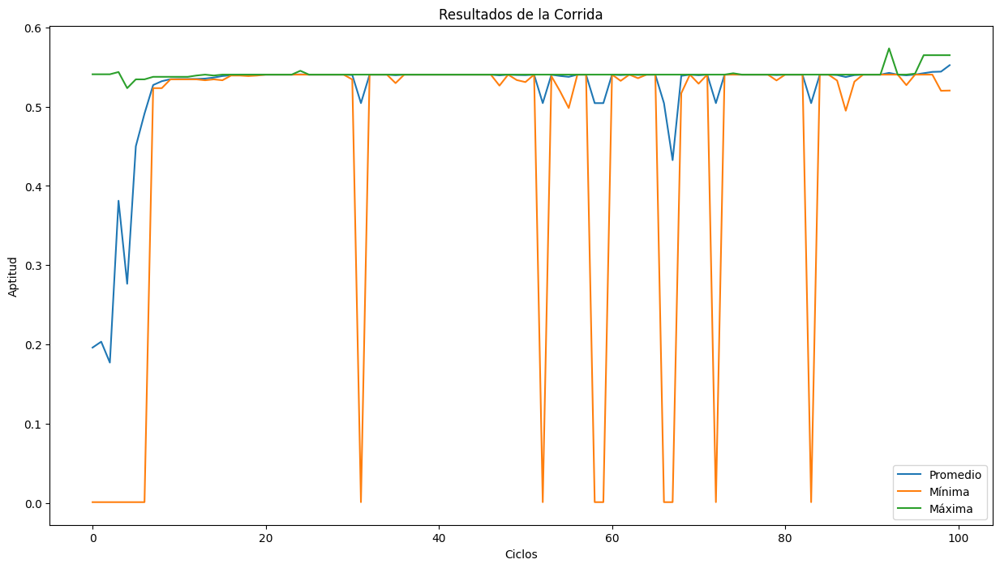

In [ ]:
#@title MOSTRAR GRÁFICO DE LA CORRIDA
plt.figure(figsize=(15,8))
plt.plot(ciclosPromAptitud)
plt.plot(ciclosMinAptitud)
plt.plot(ciclosMaxAptitud)

plt.title('Resultados de la Corrida')
plt.xlabel('Ciclos')
plt.ylabel('Aptitud')
plt.legend(['Promedio', 'Mínima', 'Máxima'], loc='lower right')

plt.show()

In [ ]:
#@title MOSTRAR ÁRBOL GENEALÓGICO

from matplotlib.colors import TwoSlopeNorm

incluir_Id_Individuo = True #@param {type:"boolean"}
pintar_Color_Aptitud = True #@param {type:"boolean"}
#@markdown (si se activa: color más ROJO significa PEOR aptitud, y más VERDE es MEJOR aptitud)

# genera gráfico
graph = networkx.MultiDiGraph(history.genealogy_tree)
graph = graph.reverse()     # Make the graph top-down

# cambia ID de individuos por detalle cromosoma
indHistory = {}
indApt = {}
for k in history.genealogy_history.keys():
  if incluir_Id_Individuo:
    auxStrLabel = str(k)+"-"+str(history.genealogy_history[k])
  else:
    auxStrLabel = str(history.genealogy_history[k])
  indHistory[k] = auxStrLabel
  if pintar_Color_Aptitud:
    indApt[auxStrLabel] = toolbox.evaluate(history.genealogy_history[k])[0]
graph = networkx.relabel_nodes(graph, indHistory)

# muestra como árbol
A = networkx.nx_agraph.to_agraph(graph)

# cambia colores por valor de aptitud
if pintar_Color_Aptitud:
  # determina mapa colores y valores mínimos/máximos
  cmap = matplotlib.colormaps.get_cmap('RdYlGn')

  # Usamos TwoSlopeNormalize importado directamente para fijar el centro de la transición de color en 0.6.
  # Esto fuerza a que los valores > 0.6 entren rápidamente en la gama de verdes del mapa RdYlGn.
  norm = TwoSlopeNorm(vmin=0.001, vcenter=0.6, vmax=1.0)

  # indica cambia color del nodo
  A.node_attr['style']='filled'
  for k in A.nodes():
      # obtiene el nodo
      n =  A.get_node(k)
      if k in indApt:
        # a partir de la aptitud asigna el color
        color = cmap(norm(indApt[k]))
        # asigna en format HEX
        n.attr['fillcolor'] =  matplotlib.colors.rgb2hex(color)

# define layout del gráfico
A.layout('dot', args='-Nfontsize=10 -Nwidth="1.0" -Nheight=".4" -Nmargin=0 -Gfontsize=8')

# muestra el gráfico
auxFile = 'genHistory.png'
A.draw(auxFile)
display(Image.open(auxFile))

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (156669200 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


In [ ]:
N_CORRIDA = 1 #@param {type:"integer"}
ARCH_RESUMEN = "log_resumen_corridas.csv"
ARCH_CICLOS  = "log_evolucion_ciclos.csv"

# 1) Resumen de la corrida (una fila por corrida)
resumen = pd.DataFrame([{
    "corrida": N_CORRIDA,
    "seleccion": tipo_seleccion,
    "cruzamiento": tipo_cruzamiento,
    "prob_mutacion": probab_mutacion,
    "poblacion": CANT_INDIVIDUOS_POBLACION,
    "ciclos": len(ciclosMaxAptitud),
    "semilla": SEMILLA,
    "mejor_aptitud": round(mejorIndCorrida.fitness.values[0], 10),
    "ciclo_mejor": mejorIndCorrida_ciclo,
    "cromosoma": str(list(mejorIndCorrida)),
    "max_final": ciclosMaxAptitud[-1],
    "prom_final": ciclosPromAptitud[-1],
    "min_final": ciclosMinAptitud[-1],
}])

# 2) Evolución por ciclo (una fila por ciclo)
evolucion = pd.DataFrame({
    "corrida": N_CORRIDA,
    "ciclo": range(len(ciclosMaxAptitud)),
    "maxima": ciclosMaxAptitud,
    "promedio": ciclosPromAptitud,
    "minima": ciclosMinAptitud,
})

def guardar(df_nuevo, archivo):
    if os.path.exists(archivo):
        previo = pd.read_csv(archivo)
        previo = previo[previo["corrida"] != N_CORRIDA]  # evita duplicar si repetís la corrida
        df_nuevo = pd.concat([previo, df_nuevo], ignore_index=True)
    df_nuevo.sort_values("corrida", kind="stable").to_csv(archivo, index=False)

guardar(resumen, ARCH_RESUMEN)
guardar(evolucion, ARCH_CICLOS)
print("Log guardado en:", ARCH_RESUMEN, "y", ARCH_CICLOS)
print(pd.read_csv(ARCH_RESUMEN).to_string())

Log guardado en: log_resumen_corridas.csv y log_evolucion_ciclos.csv
   corrida seleccion    cruzamiento  prob_mutacion  poblacion  ciclos  semilla  mejor_aptitud  ciclo_mejor                                                    cromosoma  max_final  prom_final  min_final
0        1    Torneo  Simple-1Punto            0.5         15     100       42       0.573455           92  [44, 61, 78, 45, 26, 85, 34, 89, 87, 75, 9, 59, 97, 32, 68]   0.564886    0.552262    0.52026
